# Paper-Input Gap → U.S. Printing Production: Retrospective Macro Falsification

**Independent executable research paper · 2026-10-26 · official G.17 release 2026-10-16**

This notebook uses actual frozen 2010–2026 Federal Reserve industrial production observations. It is **not** a historical point-in-time or equity-alpha backtest. The study is a falsifiable one-factor macro pilot; all numerical tables and charts below are generated from the included data. The narrative follows the repository's canonical 15-section outline and the K-Food v3 standard of hypotheses, source integrity, OOS, falsification, exposure sensitivity and explicit verdict.

## 01. Abstract

**Question:** Does paper production relative to general manufacturing forecast three-month-ahead U.S. printing output growth beyond printing persistence and the manufacturing cycle? The proposed factor is economically intuitive but must beat the historical mean and the control model. A null/negative finding is a valid final result. The source is a 2026-10-16 revised snapshot with manually transcribed year rows; publication-vintage validation is **UNKNOWN**.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from run_analysis import (main, read_official_transcription, make_panel, walk_forward,
                          metrics, moving_block_bootstrap, fast_full_predictions)
from run_analysis import ROOT
get_ipython().run_line_magic('matplotlib','inline')
plt.rcParams['figure.figsize']=(9,4.2)
# Recompute analysis and save actual OOS, robustness, placebo, bootstrap and figures.
run = main()
display(pd.DataFrame([{'N source months':run['observations'], 'OOS origins':run['oos_n'],
                       'control RMSE':run['scorecard']['control']['rmse'],
                       'full RMSE':run['scorecard']['full']['rmse'],
                       'delta':run['delta_control_minus_full']}]).round(4))

{
  "as_of": "2026-10-26",
  "source_release_date": "2026-10-16",
  "source_file_sha256": "147f482e7f59d8692fd7f2a44d0a2d5ce531156fba28325addc69e5167837459",
  "source_status": "manually transcribed official G.17 latest-revised release, not historical vintages",
  "observations": 201,
  "formation_panel": 185,
  "oos_n": 114,
  "oos_start": "2017-01-01",
  "oos_end": "2026-06-01",
  "horizon_months": 3,
  "publication_buffer_months": 1,
  "training_target_purge_months": 5,
  "scorecard": {
    "mean": {
      "n": 114,
      "rmse": 6.325795247138413,
      "mae": 4.348803144854577
    },
    "persistence": {
      "n": 114,
      "rmse": 7.07122237565824,
      "mae": 4.474763712508801
    },
    "control": {
      "n": 114,
      "rmse": 6.183754032382498,
      "mae": 3.8841333401608464
    },
    "full": {
      "n": 114,
      "rmse": 6.365870642541121,
      "mae": 4.180734642735945
    },
    "paper_only": {
      "n": 114,
      "rmse": 6.703291812776299,
      "mae": 4.6902230

,N source months,OOS origins,control RMSE,full RMSE,delta
0,201,114,6.1838,6.3659,-0.1821


**Abstract interpretation.** The main statistic is the paired control-minus-full OOS RMSE difference; positive would support incrementality, negative rejects it. The study neither asserts an investment opportunity nor extrapolates a causal industry relationship.

## 02. Research Design & Hypotheses

- **H1:** paper growth above manufacturing growth anticipates later printing output.
- **H2:** adding the paper gap reduces three-month-ahead OOS RMSE versus printing persistence and manufacturing controls.
- **H3:** any gain remains positive after excluding 2020 and under alternate release buffers and horizons.

**Null:** no incremental forecasting gain. **Failure standard:** no gain over controls and/or simple mean, unstable regimes, or no release-vintage validity. **Counterthesis:** digital substitution, paper categories unrelated to print, import sourcing, and joint business-cycle shocks. The target is *macro industrial production*, not issuer sales or stock returns.

In [2]:
assert run['historical_pit_verified'] is False
assert run['equity_alpha_tested'] is False
print('Predeclared H1/H2/H3, target NAICS 323, factor G322 minus B00004; historical PIT not verified.')

Predeclared H1/H2/H3, target NAICS 323, factor G322 minus B00004; historical PIT not verified.


## 03. Industry Context

The Federal Reserve's G.17 table maps **G322 to paper manufacturing (NAICS 322)** and **G323 to printing and related support (NAICS 323)**. Paper can be a material input to printing, but the paper aggregate includes non-print uses; manufacturing is a shared macro demand control and itself contains both sectors. This is a *candidate lead mechanism*, not evidence of causality. Sector revenue size, growth CAGR and named issuer market shares were not verified, so none are invented.

Primary source: https://www.federalreserve.gov/releases/g17/Current/ipdisk/ip_sa.txt ; release metadata: https://www.federalreserve.gov/releases/g17/Current/ipdisk/alltables.htm .

series,manufacturing_ip,paper_ip,printing_ip
date,,,
2010-01-01,91.0661,99.9533,102.8123
2010-04-01,92.8795,101.5889,104.4279
2020-01-01,98.4689,100.9335,95.3762
2026-09-01,98.4387,78.3155,74.0432


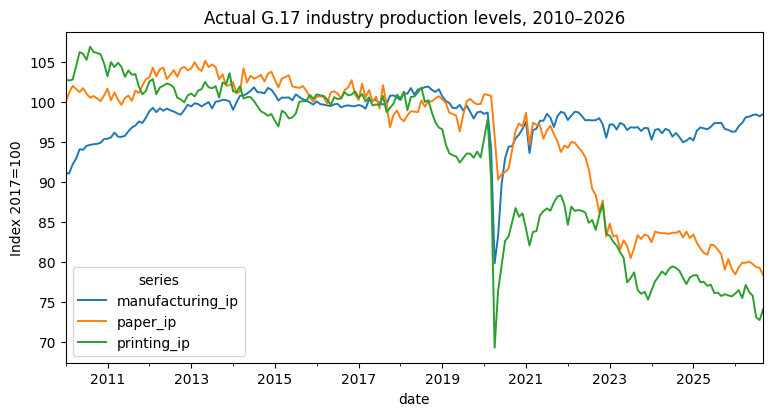

In [3]:
raw=read_official_transcription()
display(raw.iloc[[0,3,120,-1]].round(4))
ax=raw.plot(title='Actual G.17 industry production levels, 2010–2026',lw=1.4)
ax.set_ylabel('Index 2017=100');plt.show()

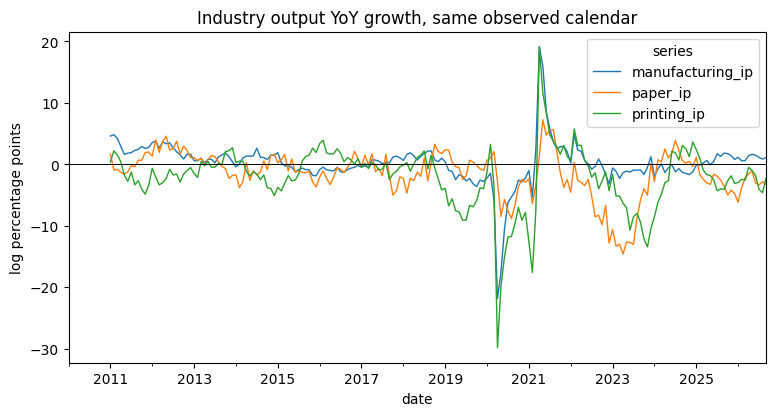

In [4]:
yoy=100*np.log(raw/raw.shift(12))
ax=yoy.plot(title='Industry output YoY growth, same observed calendar',lw=1.0)
ax.axhline(0,color='black',lw=.7);ax.set_ylabel('log percentage points');plt.show()

## 04. Data & Source Integrity

**A-grade primary government data:** 2010-01–2026-09 monthly G.17 seasonally adjusted 2017=100 indices. Original fixed-width year rows are preserved verbatim as manually transcribed text, with four-decimal precision. **B-grade:** FRED metadata for paper. **C-grade:** Fed explanatory notes. All source URLs, publication-date fields, observation windows and revision caveats are in the source register. Three cross-series spot dates are verified in the parser; full machine-to-machine row reconciliation of all 603 values remains incomplete.

In [5]:
reg=pd.read_csv(ROOT/'data/source_register.csv')
display(reg[['source_id','grade','publisher','series','source_release_date','observed_start','observed_end','historical_vintages_verified']])

,source_id,grade,publisher,series,source_release_date,observed_start,observed_end,historical_vintages_verified
0,A1,A,Board of Governors of the Federal Reserve System,G322 Paper NAICS 322,2026-10-16,2010-01,2026-09,NO
1,A2,A,Board of Governors of the Federal Reserve System,G323 Printing and related support NAICS 323,2026-10-16,2010-01,2026-09,NO
2,A3,A,Board of Governors of the Federal Reserve System,B00004 Total manufacturing,2026-10-16,2010-01,2026-09,NO
3,B1,B,Federal Reserve Bank of St. Louis FRED,IPG322S paper production series metadata,UNKNOWN,1972-01,2026-09,NO
4,C1,C,Federal Reserve Board,G.17 statistical documentation,UNKNOWN,UNKNOWN,UNKNOWN,NO


In [6]:
rawtext=(ROOT/'data/fed_g17_transcribed_rows_2026-10-16.txt').read_bytes()
sha=hashlib.sha256(rawtext).hexdigest()
print('Raw-row SHA256:',sha)
print('Expected:',run['source_file_sha256'])
assert sha==run['source_file_sha256']
assert len(raw)==201 and not raw.isna().any().any()
assert (raw>0).all().all()
print('QA PASS: 201 complete monthly observations, 3 positive series, 603 values.')

Raw-row SHA256: 147f482e7f59d8692fd7f2a44d0a2d5ce531156fba28325addc69e5167837459
Expected: 147f482e7f59d8692fd7f2a44d0a2d5ce531156fba28325addc69e5167837459
QA PASS: 201 complete monthly observations, 3 positive series, 603 values.


In [7]:
qa=pd.DataFrame({'series':raw.columns,'count':[raw[c].count() for c in raw],
                 'min':[raw[c].min() for c in raw],'max':[raw[c].max() for c in raw],
                 'last':[raw[c].iloc[-1] for c in raw]})
display(qa.round(4))

,series,count,min,max,last
0,manufacturing_ip,201,79.7713,101.8767,98.4387
1,paper_ip,201,78.3155,105.1192,78.3155
2,printing_ip,201,69.2298,106.8789,74.0432


## 05. Point-in-Time Availability

At origin **t**, the input cutoff is **t−1** (a conservative mechanical release buffer). The printing YoY target is measured at **t+3**. A training origin **j** is allowed only if **j+3+1 ≤ t−1**; thus **j ≤ t−5**. The extra month approximates publication delay, but **does not restore historical real-time values** from a 2026-10-16 revised snapshot. Original release dates, revisions and ALFRED vintages for every formation date are UNKNOWN. Results are explicitly retrospective.

In [8]:
panel=make_panel(raw,h=3,lag=1)
oos=walk_forward(panel,horizon=3,lag=1)
print('Formation panel:',len(panel),'OOS:',len(oos),'origins:',oos.origin.min().date(),'to',oos.origin.max().date())
display(oos[['origin','last_train_origin','last_train_outcome_date','outcome_date','n_train']].head(8))

Formation panel: 185 OOS: 114 origins: 2017-01-01 to 2026-06-01


,origin,last_train_origin,last_train_outcome_date,outcome_date,n_train
0,2017-01-01,2016-08-01,2016-11-01,2017-04-01,67
1,2017-02-01,2016-09-01,2016-12-01,2017-05-01,68
2,2017-03-01,2016-10-01,2017-01-01,2017-06-01,69
3,2017-04-01,2016-11-01,2017-02-01,2017-07-01,70
4,2017-05-01,2016-12-01,2017-03-01,2017-08-01,71
5,2017-06-01,2017-01-01,2017-04-01,2017-09-01,72
6,2017-07-01,2017-02-01,2017-05-01,2017-10-01,73
7,2017-08-01,2017-03-01,2017-06-01,2017-11-01,74


In [9]:
assert (oos.last_train_outcome_date < oos.origin).all()
assert (oos.n_train>=36).all()
assert (oos.outcome_date>oos.origin).all()
assert panel.loc['2018-01-01','latest_input_date']==pd.Timestamp('2017-12-01')
print('Mechanical target-label purge PASS. Historical publication-vintage test NOT PERFORMED.')

Mechanical target-label purge PASS. Historical publication-vintage test NOT PERFORMED.


## 06. Factor Construction

Define `g_s(t)=100 log(IP_s(t)/IP_s(t−12))` in log percentage points. The **fixed** signal is `F_t = g_G322(t−1) − g_B00004(t−1)`; the forecast target is `Y_t = g_G323(t+3)`. Controls are `[g_G323(t−1), g_B00004(t−1)]`; full adds `F_t`. Regression uses expanding-window Ridge with fixed penalty **8**, unpenalized intercept and training-only standardization. No future target information is used in transformations, and no coefficient is selected to maximize OOS performance.

In [10]:
display(panel[['paper_growth','mfg_growth','factor','print_momentum','target']].iloc[[0,60,120,-1]].round(3))
assert np.allclose(panel.factor,panel.paper_growth-panel.mfg_growth)
print('Factor algebra verified: paper YoY − manufacturing YoY.')

,paper_growth,mfg_growth,factor,print_momentum,target
date,,,,,
2011-02-01,1.664,4.613,-2.949,0.349,-1.746
2016-02-01,-2.085,-0.862,-1.224,3.361,1.718
2021-02-01,-2.336,-0.987,-1.348,-12.577,11.611
2026-06-01,-1.073,1.633,-2.706,-1.015,-2.204


Factor algebra verified: paper YoY − manufacturing YoY.


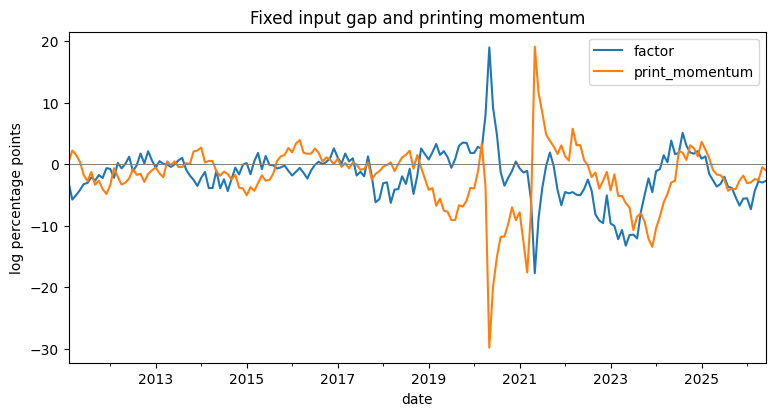

In [11]:
ax=panel[['factor','print_momentum']].plot(title='Fixed input gap and printing momentum')
ax.set_ylabel('log percentage points');ax.axhline(0,color='gray',lw=.7);plt.show()

## 07. Exposure & Transmission

The map is explicitly **industry-level**: G322 upstream paper output, G323 downstream printing output, B00004 broad manufacturing control. It does not claim dated issuer sales weights. A paper coefficient sampled uniformly from 0.7–1.3 tests sensitivity to exposure intensity, but these are proxy perturbations rather than observed firm exposures. Issuer revenue shares, fundamentals and historical security total returns are unavailable; **leave-one-company-out is not applicable**.

In [12]:
exmap=pd.read_csv(ROOT/'data/exposure_map.csv')
display(exmap[['exposure_id','industry_naics','exposure_type','signal_or_target','weight','validation']])

,exposure_id,industry_naics,exposure_type,signal_or_target,weight,validation
0,paper_industry,322,industry proxy,input paper output,1.0,official code G322
1,printing_industry,323,industry proxy,outcome printing output,1.0,official code G323
2,manufacturing,31-33,cycle control,input total manufacturing,1.0,official code B00004
3,issuer_mapping,UNKNOWN,issuer exposure,NOT TESTED,NaN,not established


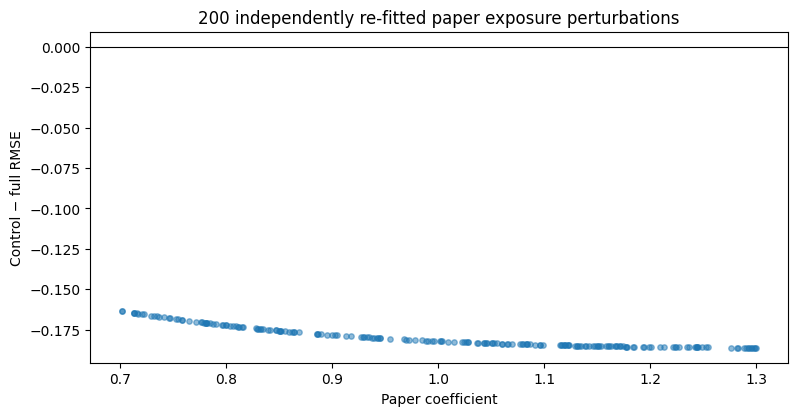

Share with positive incremental gain: 0.0


In [13]:
exposure=pd.read_csv(ROOT/'results/exposure_perturbation_200.csv')
fig,ax=plt.subplots();ax.scatter(exposure.weight,exposure.delta_control_minus_full,s=15,alpha=.5)
ax.axhline(0,color='black',lw=.8);ax.set(xlabel='Paper coefficient',ylabel='Control − full RMSE',title='200 independently re-fitted paper exposure perturbations');plt.show()
print('Share with positive incremental gain:',round((exposure.delta_control_minus_full>0).mean(),3))

## 08. Outcomes & Baselines

The dependent variable is *printing YoY output growth three months after formation*. The five comparators are (i) historical training mean, (ii) last available printing YoY, (iii) printing+manufacturing Ridge controls, (iv) those controls plus paper gap, and (v) paper-gap-only Ridge. All use identical origins, with labels purged until available. Macro RMSE/MAE are appropriate; security Rank IC, long-short spreads and execution-adjusted returns are **not defined** for this single aggregate outcome.

In [14]:
score=pd.read_csv(ROOT/'results/scorecard.csv')
display(score.round(4))
assert score.n.nunique()==1 and score.n.iloc[0]==len(oos)

,model,n,rmse,mae
0,mean,114,6.3258,4.3488
1,persistence,114,7.0712,4.4748
2,control,114,6.1838,3.8841
3,full,114,6.3659,4.1807
4,paper_only,114,6.7033,4.6902


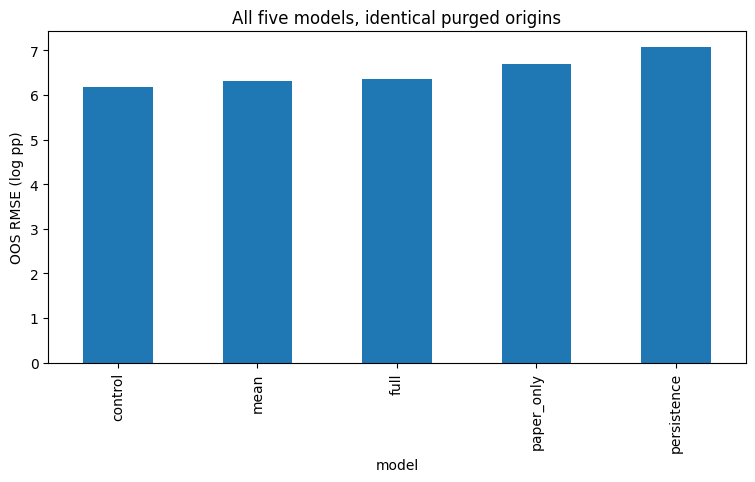

In [15]:
fig,ax=plt.subplots();score.sort_values('rmse').plot.bar(x='model',y='rmse',ax=ax,legend=False)
ax.set(ylabel='OOS RMSE (log pp)',title='All five models, identical purged origins');plt.show()

In [16]:
m=metrics(oos)
for k in m:assert abs(m[k]['rmse']-score.set_index('model').loc[k,'rmse'])<1e-9
print('Independent RMSE/MAE recalculation agrees with saved scorecard.')

Independent RMSE/MAE recalculation agrees with saved scorecard.


## 09. Empirical Findings

The primary OOS improvement is `RMSE_control − RMSE_full`; **positive** would favor the paper gap. The realized difference is **negative**. OOS RMSE alone cannot establish causal transmission or point-in-time tradability. Inspect forecasts and cumulative paired losses, especially around pandemic-era shocks.

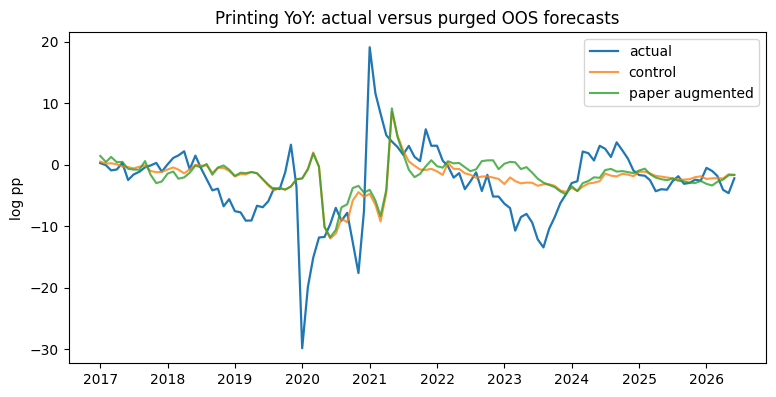

In [17]:
fig,ax=plt.subplots();ax.plot(oos.origin,oos.actual,label='actual',lw=1.6)
ax.plot(oos.origin,oos.control,label='control',alpha=.8)
ax.plot(oos.origin,oos.full,label='paper augmented',alpha=.8)
ax.set(title='Printing YoY: actual versus purged OOS forecasts',ylabel='log pp');ax.legend();plt.show()

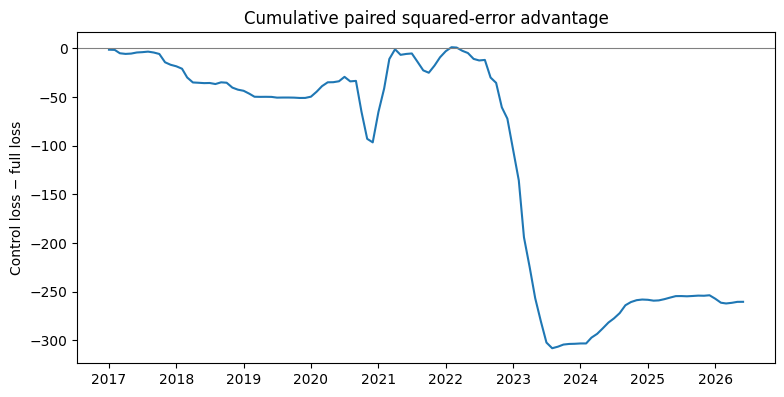

Control-minus-full RMSE: -0.1821


In [18]:
sq_c=(oos.actual-oos.control)**2;sq_f=(oos.actual-oos.full)**2
fig,ax=plt.subplots();ax.plot(oos.origin,(sq_c-sq_f).cumsum())
ax.axhline(0,color='gray',lw=.8);ax.set(title='Cumulative paired squared-error advantage',ylabel='Control loss − full loss');plt.show()
print('Control-minus-full RMSE:',round(m['control']['rmse']-m['full']['rmse'],4))

In [19]:
loss=pd.DataFrame({'origin':oos.origin,'control_sq':sq_c,'full_sq':sq_f,'difference':sq_c-sq_f})
display(loss.assign(year=loss.origin.dt.year).groupby('year')[['control_sq','full_sq','difference']].mean().round(2))

,control_sq,full_sq,difference
year,,,
2017,0.98,2.38,-1.40
2018,9.03,11.17,-2.13
2019,24.97,25.68,-0.71
2020,151.00,154.81,-3.81
2021,115.61,108.32,7.29
2022,4.79,10.05,-5.26
2023,38.47,57.76,-19.29
2024,15.38,11.59,3.79
2025,1.53,1.16,0.37


## 10. Robustness & Placebos

The **1,000-refit** placebo uses 12-month block-aware resampling of the factor time series and refits the challenger each draw. Its upper-tail fraction is **exploratory**, not an exact permutation p-value under exchangeability. A **2,000-draw paired moving-block bootstrap** samples OOS origin blocks of length 12 to retain local serial dependence; the interval is descriptive and not a substitute for an untouched prospective holdout. The 200 paper-weight perturbations and leave-one-year-out ablations further test stability.

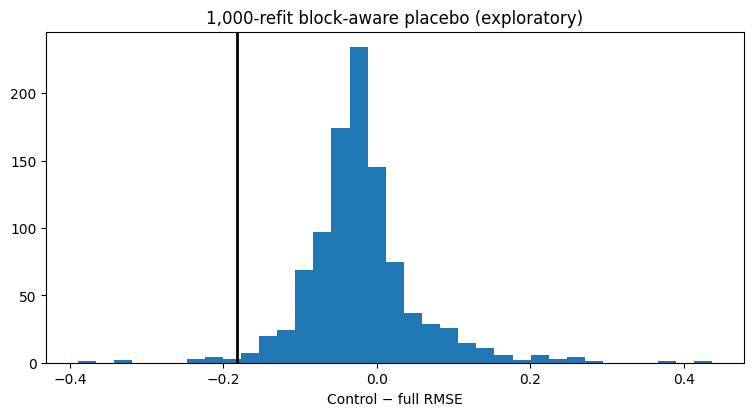

Exploratory upper-tail fraction: 0.987012987012987


In [20]:
pl=pd.read_csv(ROOT/'results/block_placebo_1000.csv').delta_rmse
fig,ax=plt.subplots();ax.hist(pl,bins=35);ax.axvline(run['delta_control_minus_full'],color='black',lw=2)
ax.set(title='1,000-refit block-aware placebo (exploratory)',xlabel='Control − full RMSE');plt.show()
print('Exploratory upper-tail fraction:',run['exploratory_block_shuffle_tail_fraction'])

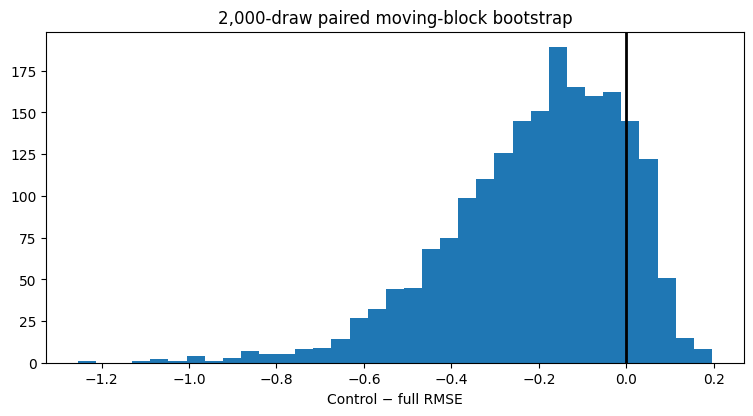

Paired 95% percentile interval: [-0.6566778   0.08519233]


In [21]:
bs=pd.read_csv(ROOT/'results/bootstrap_2000.csv').delta_rmse
fig,ax=plt.subplots();ax.hist(bs,bins=35);ax.axvline(0,color='black',lw=2)
ax.set(title='2,000-draw paired moving-block bootstrap',xlabel='Control − full RMSE');plt.show()
print('Paired 95% percentile interval:',np.quantile(bs,[.025,.975]))

In [22]:
ly=pd.read_csv(ROOT/'results/leave_one_year_out.csv')
display(ly.round(4))
assert (ly.delta_control_minus_full<0).all()
print('Every single-year exclusion remains negative. This is NOT leave-one-company-out.')

,excluded_year,n,delta_control_minus_full
0,2017,102,-0.1805
1,2018,102,-0.1760
2,2019,102,-0.1929
3,2020,102,-0.2065
4,2021,102,-0.3073
5,2022,102,-0.1474
6,2023,102,-0.0230
7,2024,102,-0.2304
8,2025,102,-0.1961
9,2026,108,-0.1827


Every single-year exclusion remains negative. This is NOT leave-one-company-out.


## 11. Regime Sensitivity

Test 1-, 3-, and 6-month forecast horizons crossed with 1-, 2-, and 3-month input publication buffers. Compare post-2021, pre-2020 and exclude-2020 subsets without refitting their original OOS forecasts. Each is a *sensitivity*, not a new prespecified independent experiment; overlapping forward YoY targets make naive t-tests inappropriate.

In [23]:
rob=pd.read_csv(ROOT/'results/robustness.csv')
display(rob[['horizon_months','publication_buffer_months','regime','n','delta_control_minus_full']].round(3))

,horizon_months,publication_buffer_months,regime,n,delta_control_minus_full
0,1,1,NaN,116,-0.190
1,1,2,NaN,116,-0.230
2,1,3,NaN,116,-0.185
3,3,1,NaN,114,-0.182
4,3,2,NaN,114,-0.128
5,3,3,NaN,114,-0.074
6,6,1,NaN,111,-0.313
7,6,2,NaN,111,-0.572
8,6,3,NaN,111,-0.652
9,3,1,exclude_2020,102,-0.206


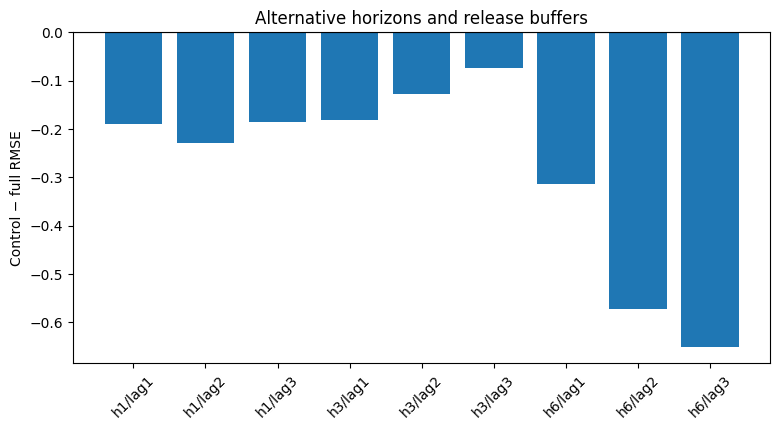

In [24]:
r=rob[rob.regime.isna()]
fig,ax=plt.subplots();ax.bar(np.arange(len(r)),r.delta_control_minus_full)
ax.axhline(0,color='black');ax.set(xticks=np.arange(len(r)),xticklabels=[f'h{h}/lag{l}' for h,l in zip(r.horizon_months,r.publication_buffer_months)],
 ylabel='Control − full RMSE',title='Alternative horizons and release buffers');plt.xticks(rotation=45);plt.show()

## 12. Bias Audit & Verdict

**Historical revisions:** NOT PIT. **Publication timing:** one-month buffers are assumptions, not verified dates. **Selection/multiple testing:** one predeclared factor in this study, but broader repo studies create research-family selection. **Survivorship:** no security universe. **Mechanics:** printing and paper share aggregate demand; manufacturing controls include both, so causal claims fail. **Pandemic/structural change:** explicit regime checks. **Transaction costs/capacity:** cannot be assessed without securities. **Verdict:** negative retrospective macro-factor falsification; neither issuer fundamental lead nor investable equity alpha is established.

In [25]:
audit=pd.DataFrame([
('historical vintage','UNKNOWN; latest revised 2026-10-16','blocking for PIT'),
('training label purge','enforced j<=t−5','mechanical PASS'),
('sector selection','single prespecified pair; repository family multiple tests','unadjusted'),
('issuer exposure','not collected','no issuer inference'),
('returns / costs','not collected','no trading alpha'),
('result','negative RMSE increment','retain failed hypothesis')],columns=['risk','evidence','verdict'])
display(audit)

,risk,evidence,verdict
0,historical vintage,UNKNOWN; latest revised 2026-10-16,blocking for PIT
1,training label purge,enforced j<=t−5,mechanical PASS
2,sector selection,single prespecified pair; repository family mu...,unadjusted
3,issuer exposure,not collected,no issuer inference
4,returns / costs,not collected,no trading alpha
5,result,negative RMSE increment,retain failed hypothesis


## 13. Reproduction

Run `python run_analysis.py`, `PYTHONPATH=. pytest -q tests`, then execute this notebook from a clean checkout with declared `requirements.txt`. The notebook's first code cell re-generates all numerical outputs from the frozen source rows. The committed notebook stores every output and contains no error cells. The root repository's structural validator is a **separate** gate, and a successful structure check does not validate original-release PIT status.

In [26]:
files=[ROOT/'results/metrics.json',ROOT/'results/walk_forward_oos.csv',ROOT/'results/block_placebo_1000.csv',
       ROOT/'results/bootstrap_2000.csv',ROOT/'data/source_register.csv']
assert all(x.exists() and x.stat().st_size>0 for x in files)
print('Core generated artifacts exist:');print('\n'.join(f'{x.relative_to(ROOT)}: {x.stat().st_size:,} bytes' for x in files))

Core generated artifacts exist:
results/metrics.json: 1,636 bytes
results/walk_forward_oos.csv: 18,881 bytes
results/block_placebo_1000.csv: 21,057 bytes
results/bootstrap_2000.csv: 41,236 bytes
data/source_register.csv: 2,831 bytes


In [27]:
figures=sorted((ROOT/'figures').glob('*.svg'))
assert len(figures)>=3
print(f'{len(figures)} computed SVG figures persisted:')
print('\n'.join(x.name for x in figures))

10 computed SVG figures persisted:
01_output_levels.svg
02_growth_rates.svg
03_factor_and_momentum.svg
04_oos_forecasts.svg
05_baseline_scorecard.svg
06_cumulative_loss.svg
07_placebo.svg
08_bootstrap.svg
09_exposure.svg
10_robustness.svg


## 14. Next-Stage Protocol

1. Obtain original full Fed G.17 text download and reconcile all 603 transcribed values with a machine parser; record immutable upstream hash.
2. Build ALFRED/G.17 archived-vintage release-calendar panel and rerun formation-time filters.
3. Decompose paper into printing-grade versus packaging/tissue; avoid tautological input/output overlaps.
4. Obtain dated SEC issuer segment sales, filing publication dates and survivorship-complete issuer universe; evaluate fundamentals independently.
5. Only after successful vintage-valid fundamental tests, evaluate dividend-adjusted total returns, sector controls, costs, multiple testing and an untouched holdout.

In [28]:
next_steps=pd.DataFrame({'priority':[1,2,3,4,5],
 'deliverable':['machine-verified upstream raw hash','historical release-vintage panel','subindustry paper demand split',
                'dated issuer revenue + filings','total returns / costs / future holdout'],
 'current_status':['NOT DONE']*5})
display(next_steps)

,priority,deliverable,current_status
0,1,machine-verified upstream raw hash,NOT DONE
1,2,historical release-vintage panel,NOT DONE
2,3,subindustry paper demand split,NOT DONE
3,4,dated issuer revenue + filings,NOT DONE
4,5,total returns / costs / future holdout,NOT DONE


## 15. Sources & Artifacts

**A — Federal Reserve G.17 official release (2026-10-16):** https://www.federalreserve.gov/releases/g17/Current/ipdisk/ip_sa.txt ; https://www.federalreserve.gov/releases/g17/Current/ipdisk/alltables.htm .

**B — FRED paper series metadata:** https://fred.stlouisfed.org/series/IPG322S .

**C — Federal Reserve explanatory methodology:** https://www.federalreserve.gov/releases/g17/About.htm .

The `data/source_register.csv` records source grades, URLs, release dates, observation periods, revisions and historical-vintage caveats. The frozen raw-row transcription, derived panel, source QA, 10 figures, OOS scorecard, 1,000 placebo draws, 2,000 bootstrap draws, 200 exposure refits, sensitivity tables, tests and notebook execution log are bundled with this notebook.

In [29]:
display(reg[['source_id','grade','source_url','source_release_date','revisions']])
print('FINAL VERDICT: NEGATIVE RETROSPECTIVE MACRO PILOT; NOT PIT; NOT INVESTABLE EQUITY ALPHA.')

,source_id,grade,source_url,source_release_date,revisions
0,A1,A,https://www.federalreserve.gov/releases/g17/Cu...,2026-10-16,Revisions and seasonal rebasing occur
1,A2,A,https://www.federalreserve.gov/releases/g17/Cu...,2026-10-16,Revisions and seasonal rebasing occur
2,A3,A,https://www.federalreserve.gov/releases/g17/Cu...,2026-10-16,Revisions and seasonal rebasing occur
3,B1,B,https://fred.stlouisfed.org/series/IPG322S,UNKNOWN,FRED reproduces latest revised G17 series
4,C1,C,https://www.federalreserve.gov/releases/g17/Ab...,UNKNOWN,Annual benchmark and monthly revisions possible


FINAL VERDICT: NEGATIVE RETROSPECTIVE MACRO PILOT; NOT PIT; NOT INVESTABLE EQUITY ALPHA.
